# Proyecto integrador — Big Data 2026-2
## Readmisión hospitalaria temprana en pacientes con diabetes: análisis de 101 766 hospitalizaciones con PySpark

**Integrantes:**
1. Maria del Pilar Guzman Murillo
2. Daniel Felipe Arenas Quiroga
3. David Fernando Rico Mendivelso

**Repositorio:** https://github.com/dfarenasq/bigdata-readmision-diabetes

**Curso:** Big Data 2026-2 — Facultad de Ingeniería de Sistemas, Universidad Santo Tomás Seccional Tunja

**Contenido:** T1 contexto · T2 dataset · T3 arquitectura · T4 ingesta (bronce) · T5 calidad y limpieza (plata) · T6 PySpark y Spark SQL (oro) · T7 análisis · T9 conclusiones · Electiva E: valor estimado

In [1]:
import os, io, zipfile, hashlib, datetime, urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
NAVY, CYAN, RED, GRAY = "#222656", "#00C6D2", "#E4505A", "#8A8FA3"
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

BRONZE, SILVER, GOLD, FIGS = "data/bronze", "data/silver", "data/gold", "figs"
for d in (BRONZE, SILVER, GOLD, FIGS):
    os.makedirs(d, exist_ok=True)

def fmt_p(p):
    return f"{p:.1e}" if p > 0 else "< 1e-300 (por debajo de la precisión numérica)"

def guardar(nombre):
    plt.savefig(f"{FIGS}/{nombre}.png", dpi=160, bbox_inches="tight")

## T1. Contexto, problema y preguntas de análisis

**Sector:** salud — gestión hospitalaria de pacientes con diabetes.

**Problema:** una readmisión en los 30 días siguientes al egreso suele indicar que el paciente salió sin un control adecuado de su enfermedad. Además de afectar al paciente, encarece la atención: en EE. UU. el costo promedio de una readmisión a 30 días en adultos fue de USD 15 200 en 2018 (Weiss y Jiang, 2021). Identificar qué perfiles de paciente y qué prácticas hospitalarias se asocian a la readmisión temprana permite enfocar los programas de seguimiento.

**Usuarios de la información:** directivos y comités de calidad hospitalaria, equipos de endocrinología y planeación de egresos, aseguradores.

**Preguntas de análisis (medibles):**
1. **P1.** ¿Cómo cambia la tasa de readmisión temprana (< 30 días) según el número de hospitalizaciones del paciente en el año anterior?
2. **P2.** ¿Los pacientes a quienes se les midió la hemoglobina glicosilada (HbA1c) durante la hospitalización tienen una tasa de readmisión temprana distinta de quienes no?
3. **P3.** ¿Cómo varían la estancia hospitalaria, el número de medicamentos y la readmisión temprana entre grupos de edad?
4. **P4.** ¿Qué grupos de diagnóstico principal y qué destinos de egreso concentran las tasas más altas de readmisión temprana?

## T2. Selección y descripción del dataset

| Atributo | Valor |
|---|---|
| Nombre | Diabetes 130-US Hospitals for Years 1999-2008 |
| Fuente | UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/296 (DOI 10.24432/C5230J) |
| Origen de los datos | Extracto anonimizado de la base Health Facts (Cerner), 130 hospitales de EE. UU., 1999–2008 (Strack et al., 2014) |
| Licencia | Creative Commons Attribution 4.0 (CC BY 4.0) |
| Fecha de descarga | la registra la celda de ingesta en `data/bronze/_metadata.txt` |
| Volumen | 101 766 filas × 50 columnas (≈ 18 MB) + tabla de códigos `IDs_mapping.csv` |
| Unidad de análisis | una hospitalización (encuentro) de un paciente con diagnóstico de diabetes |

El diccionario de datos completo (50 columnas) se genera con código en T5.1 y se incluye en el anexo del informe.

**Datos personales (Ley 1581 de 2012):** el dataset no tiene nombres ni documentos, pero sí identificadores de paciente y de encuentro (`patient_nbr`, `encounter_id`) y un dato sensible según el artículo 5 de la ley (origen racial, columna `race`), además de datos de salud. Tratamiento aplicado: los dos identificadores se seudonimizan con SHA-256 y sal, la columna `race` se elimina de las capas analíticas porque ninguna pregunta la necesita, y el dashboard solo muestra agregados.

**Contexto reutilizable:** el contexto no se reutiliza en otras electivas; todo el trabajo corresponde a Big Data.

## T3. Arquitectura del flujo de datos (Electiva B: capas bronce / plata / oro)

```
UCI Repository (ZIP) ──descarga por código──►  BRONCE   data/bronze/diabetic_data.csv + IDs_mapping.csv + _metadata.txt
                                                   │  Pandas: faltantes, códigos nulos, exclusiones, seudonimización, tipos
                                                   ▼
                                               PLATA    data/silver/encuentros.parquet  (99 340 encuentros limpios)
                                                   │  PySpark: filter, groupBy, Spark SQL, join con tablas de códigos
                                                   ▼
                                               ORO      data/gold/*.parquet  (tasas por pregunta)
                                                   │
                                                   ▼
                                               CONSUMO  app.py — Streamlit + Plotly
```

| Capa | Contenido | Formato | Herramienta | Responsable |
|---|---|---|---|---|
| Bronce | Datos originales sin modificar y metadatos de descarga | CSV | Python (urllib, zipfile) | Maria del Pilar Guzman Murillo |
| Plata | Encuentros limpios, seudonimizados y tipados | Parquet | Pandas / NumPy | David Fernando Rico Mendivelso |
| Oro | Tablas agregadas que responden P1–P4 | Parquet | PySpark / Spark SQL | David Fernando Rico Mendivelso |
| Consumo | Dashboard interactivo | — | Streamlit + Plotly | Daniel Felipe Arenas Quiroga |

**Responsable de la fuente:** Maria del Pilar Guzman Murillo (descarga, verificación de licencia y versión).

## T4. Ingesta (capa bronce)

In [2]:
UCI_ZIP = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
ESPEJO = "https://raw.githubusercontent.com/lugooe/Diabetes/main/"   # copia en GitHub del mismo archivo, por si UCI no responde
RAW, MAP = f"{BRONZE}/diabetic_data.csv", f"{BRONZE}/IDs_mapping.csv"

if not os.path.exists(RAW):
    try:
        with urllib.request.urlopen(UCI_ZIP, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        for nombre in z.namelist():
            if nombre.endswith(("diabetic_data.csv", "IDs_mapping.csv")):
                with open(f"{BRONZE}/{os.path.basename(nombre)}", "wb") as f:
                    f.write(z.read(nombre))
        origen = UCI_ZIP
    except Exception as e:
        print("UCI no disponible, se usa el espejo:", e)
        urllib.request.urlretrieve(ESPEJO + "diabetic_data.csv", RAW)
        urllib.request.urlretrieve(ESPEJO + "IDs_mapping.csv", MAP)
        origen = ESPEJO
    sha = hashlib.sha256(open(RAW, "rb").read()).hexdigest()
    with open(f"{BRONZE}/_metadata.txt", "w") as f:
        f.write(f"origen={origen}\nfecha_descarga={datetime.date.today().isoformat()}\n"
                f"licencia=CC BY 4.0\nsha256={sha}\n")

print(open(f"{BRONZE}/_metadata.txt").read())
raw = pd.read_csv(RAW, dtype=str)          # todo como texto: así se ve el dato tal como llega
print(f"Volumen: {raw.shape[0]:,} filas x {raw.shape[1]} columnas | {os.path.getsize(RAW)/1e6:.1f} MB")
raw.head(3)

UCI no disponible, se usa el espejo: <urlopen error Tunnel connection failed: 403 Forbidden (agent proxy: no rule or network setting allows this host)>


origen=https://raw.githubusercontent.com/lugooe/Diabetes/main/
fecha_descarga=2026-11-22
licencia=CC BY 4.0
sha256=0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97



Volumen: 101,766 filas x 50 columnas | 19.2 MB


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


In [3]:
# Lectura con PySpark (en Colab: !pip install pyspark)
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.appName("ReadmisionDiabetes").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

sraw = spark.read.csv(RAW, header=True, inferSchema=True)
print("Filas leídas por Spark:", sraw.count(), "| columnas:", len(sraw.columns))
assert sraw.count() == len(raw)
sraw.select("encounter_id", "age", "race", "weight", "A1Cresult", "readmitted").show(5)

Filas leídas por Spark: 101766 | columnas: 50


+------------+-------+---------------+------+---------+----------+
|encounter_id|    age|           race|weight|A1Cresult|readmitted|
+------------+-------+---------------+------+---------+----------+
|     2278392| [0-10)|      Caucasian|     ?|     None|        NO|
|      149190|[10-20)|      Caucasian|     ?|     None|       >30|
|       64410|[20-30)|AfricanAmerican|     ?|     None|        NO|
|      500364|[30-40)|      Caucasian|     ?|     None|        NO|
|       16680|[40-50)|      Caucasian|     ?|     None|        NO|
+------------+-------+---------------+------+---------+----------+
only showing top 5 rows


## T5. Diagnóstico de calidad y limpieza (capa plata)

### 5.1 Diagnóstico por columna (antes de limpiar) y diccionario de datos

In [4]:
NUM = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

def atipicos_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

diag = []
for c in raw.columns:
    s = raw[c]
    num = pd.to_numeric(s, errors="coerce")
    diag.append({
        "columna": c,
        "tipo_leido": "texto",
        "tipo_real": "entero" if c in NUM else ("identificador" if c in ("encounter_id", "patient_nbr") else
                     ("código" if c.endswith("_id") else "categórica")),
        "faltantes_'?'": int((s == "?").sum()),
        "pct_faltante": round((s == "?").mean() * 100, 2),
        "valores_únicos": s.nunique(),
        "atípicos_IQR": atipicos_iqr(num) if c in NUM else None,
        "ejemplo": s.iloc[0],
    })
diag = pd.DataFrame(diag)
diag.to_csv(f"{FIGS}/diccionario_diagnostico.csv", index=False)

print("Filas duplicadas completas:", raw.duplicated().sum())
print("encounter_id repetidos:", raw['encounter_id'].duplicated().sum())
print("Pacientes únicos:", raw['patient_nbr'].nunique(), "| pacientes con más de un encuentro:",
      (raw['patient_nbr'].value_counts() > 1).sum())
print("gender inválido:", (raw['gender'] == 'Unknown/Invalid').sum())
print("Columnas con un solo valor:", [c for c in raw.columns if raw[c].nunique() == 1])
diag.sort_values("pct_faltante", ascending=False).head(12)

Filas duplicadas completas: 0
encounter_id repetidos: 0
Pacientes únicos: 71518 | pacientes con más de un encuentro: 16773
gender inválido: 3
Columnas con un solo valor: ['examide', 'citoglipton']


,columna,tipo_leido,tipo_real,faltantes_'?',pct_faltante,valores_únicos,atípicos_IQR,ejemplo
5,weight,texto,categórica,98569,96.86,10,NaN,?
11,medical_specialty,texto,categórica,49949,49.08,73,NaN,Pediatrics-Endocrinology
10,payer_code,texto,categórica,40256,39.56,18,NaN,?
2,race,texto,categórica,2273,2.23,6,NaN,Caucasian
20,diag_3,texto,categórica,1423,1.40,790,NaN,?
19,diag_2,texto,categórica,358,0.35,749,NaN,?
18,diag_1,texto,categórica,21,0.02,717,NaN,250.83
6,admission_type_id,texto,código,0,0.00,8,NaN,6
1,patient_nbr,texto,identificador,0,0.00,71518,NaN,8222157
0,encounter_id,texto,identificador,0,0.00,101766,NaN,2278392


In [5]:
# Valores que significan 'sin dato' escritos como un código válido en las columnas *_id
mapa_raw = open(MAP).read().split("\n,\n")
dims = {}
for bloque in mapa_raw:
    t = pd.read_csv(io.StringIO(bloque.strip()), dtype=str, keep_default_na=False)   # 'NULL' debe leerse como texto
    nombre = t.columns[0]
    t.columns = ["id", "descripcion"]
    dims[nombre] = t[t.id != ""]
NULOS_TXT = ("NULL", "Not Available", "Not Mapped", "Unknown/Invalid")
for col, t in dims.items():
    codigos_nulos = t.loc[t.descripcion.str.strip().isin(NULOS_TXT), "id"].tolist()
    print(f"{col}: códigos que equivalen a nulo {codigos_nulos} -> {raw[col].isin(codigos_nulos).sum():,} filas")

# Faltante 'estructural': A1Cresult y max_glu_serum vacíos significan 'prueba no realizada'
print("\nA1Cresult:", raw['A1Cresult'].fillna('vacío').value_counts().to_dict())
print("max_glu_serum:", raw['max_glu_serum'].fillna('vacío').value_counts().to_dict())

admission_type_id: códigos que equivalen a nulo ['5', '6', '8'] -> 10,396 filas
discharge_disposition_id: códigos que equivalen a nulo ['18', '25', '26'] -> 4,680 filas
admission_source_id: códigos que equivalen a nulo ['9', '15', '17', '20', '21'] -> 7,067 filas

A1Cresult: {'vacío': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
max_glu_serum: {'vacío': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}


### 5.2 Decisiones de limpieza

| # | Problema encontrado | Decisión | Justificación |
|---|---|---|---|
| 1 | Faltantes escritos como `?` (weight, payer_code, medical_specialty, race, diag_1–3) | Convertir `?` a nulo | Un `?` leído como categoría falsea conteos y proporciones. |
| 2 | `weight` con 96,9 % de faltantes y `payer_code` con 39,6 % | Eliminar ambas columnas | No hay forma razonable de imputarlas y ninguna pregunta las usa. |
| 3 | `race` es un dato sensible (Ley 1581, art. 5) | Eliminar de las capas plata y oro | Ninguna pregunta la necesita; minimizar datos sensibles. |
| 4 | `patient_nbr` y `encounter_id` identifican personas | Seudonimizar con SHA-256 + sal | Se conserva la trazabilidad sin exponer el identificador original. |
| 5 | `gender = Unknown/Invalid` (3 filas) | Eliminar filas | Categoría inválida y despreciable en volumen. |
| 6 | Egresos por fallecimiento u hospicio (códigos 11, 13, 14, 19, 20, 21) | Excluir encuentros | Un paciente fallecido o en hospicio no puede ser readmitido; incluirlo baja la tasa de forma artificial (mismo criterio de Strack et al., 2014). |
| 7 | Códigos de "NULL / Not Available / Not Mapped" en admission_type, admission_source y discharge | Recodificar como `Desconocido` | Son faltantes disfrazados de código válido. |
| 8 | `A1Cresult` y `max_glu_serum` vacíos | Recodificar como `No medido` | El vacío significa que la prueba no se hizo: es información, no un faltante. |
| 9 | `medical_specialty` con 49,1 % de faltantes | Rellenar con `Desconocida` | Se conserva la fila; la especialidad no es variable central. |
| 9b | `diag_1`, `diag_2`, `diag_3` con pocos faltantes | `diag_1` faltante pasa al grupo `Otros`; `diag_2` y `diag_3` se dejan nulos | Solo el diagnóstico principal se analiza; los secundarios se conservan como están. |
| 10 | `examide` y `citoglipton` tienen un solo valor | Eliminar columnas | No aportan información. |
| 11 | `age` es texto con intervalos `[70-80)` | Etiqueta `70-79` ordenada + edad media numérica (75) | Permite ordenar y calcular. |
| 12 | Códigos ICD-9 en `diag_1` | Agrupar en 9 categorías clínicas (Strack et al., 2014) | Más de 700 códigos distintos no se pueden comparar uno a uno. |
| 13 | Colas largas en visitas previas, medicamentos y laboratorios | Marcar atípicos, no eliminarlos: regla IQR en medicamentos, laboratorios y estancia; percentil 99 en visitas previas (su IQR es 0) | Son pacientes reales de alto uso, justamente los de mayor riesgo. |
| 14 | Pacientes con varios encuentros (16 773 pacientes) | Mantener todos los encuentros y marcar el primero de cada paciente | Las tasas usan todos los encuentros; las pruebas estadísticas se repiten con el primer encuentro para no contar dos veces al mismo paciente. |
| 15 | Variable objetivo con 3 niveles (`NO`, `>30`, `<30`) | Crear `readmit_30` = 1 si `<30` | La pregunta de negocio es la readmisión temprana. |

In [6]:
df = raw.replace("?", np.nan).copy()                                                    # decisión 1
df = df.drop(columns=["weight", "payer_code", "race", "examide", "citoglipton"])          # decisiones 2, 3, 10
df = df[df["gender"] != "Unknown/Invalid"]                                               # decisión 5
FALLECIDO_HOSPICIO = ["11", "13", "14", "19", "20", "21"]
df = df[~df["discharge_disposition_id"].isin(FALLECIDO_HOSPICIO)]                        # decisión 6

for c in NUM:
    df[c] = df[c].astype(int)

# decisión 7: descripción en español; los códigos de 'sin dato' quedan como 'Desconocido'
TIPO_ADMISION = {"1": "Emergencia", "2": "Urgente", "3": "Electiva", "4": "Recién nacido", "7": "Centro de trauma"}
ORIGEN_ADMISION = {"1": "Remisión médica", "2": "Remisión de clínica", "3": "Remisión de aseguradora",
                   "4": "Traslado desde hospital", "5": "Traslado desde centro de enfermería", "6": "Traslado desde otra institución",
                   "7": "Servicio de urgencias", "8": "Autoridad judicial", "10": "Traslado desde hospital de acceso crítico",
                   "11": "Parto normal", "13": "Recién nacido enfermo", "14": "Nacimiento extramural",
                   "22": "Traslado interno con cuenta aparte", "25": "Traslado desde cirugía ambulatoria"}
EGRESO = {"1": "Casa", "2": "Otro hospital de corta estancia", "3": "Centro de enfermería especializada",
          "4": "Centro de cuidado intermedio", "5": "Otra institución de hospitalización", "6": "Casa con atención domiciliaria",
          "7": "Alta voluntaria", "8": "Casa con terapia intravenosa", "9": "Hospitalizado en el mismo hospital",
          "10": "Neonato a otro hospital", "12": "Regresa como paciente ambulatorio", "15": "Cama de transición (Medicare)",
          "16": "Otra institución ambulatoria", "17": "Esta institución, ambulatorio", "22": "Centro de rehabilitación",
          "23": "Hospital de larga estancia", "24": "Centro de enfermería (Medicaid)", "27": "Institución federal",
          "28": "Hospital psiquiátrico", "30": "Otra institución de salud"}
for col, mapa in [("admission_type_id", TIPO_ADMISION), ("admission_source_id", ORIGEN_ADMISION),
                  ("discharge_disposition_id", EGRESO)]:
    df[col.replace("_id", "")] = df[col].map(mapa).fillna("Desconocido")

df["A1Cresult"] = df["A1Cresult"].fillna("No medido")                                    # decisión 8
df["max_glu_serum"] = df["max_glu_serum"].fillna("No medido")
df["hba1c_medida"] = (df["A1Cresult"] != "No medido").astype(int)
df["medical_specialty"] = df["medical_specialty"].fillna("Desconocida")                  # decisión 9

EDADES = ["0-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90-99"]
df["grupo_edad"] = df["age"].str.extract(r"\[(\d+)-(\d+)\)").apply(lambda r: f"{r[0]}-{int(r[1])-1}", axis=1)  # decisión 11
df["edad_media"] = df["age"].str.extract(r"\[(\d+)-").astype(int)[0] + 5

def grupo_icd9(c):                                                                        # decisión 12
    if pd.isna(c) or c[0] in "VE":
        return "Otros"
    x = float(c)
    if 390 <= x <= 459 or int(x) == 785: return "Circulatorio"
    if 460 <= x <= 519 or int(x) == 786: return "Respiratorio"
    if 520 <= x <= 579 or int(x) == 787: return "Digestivo"
    if int(x) == 250: return "Diabetes"
    if 800 <= x <= 999: return "Lesiones"
    if 710 <= x <= 739: return "Musculoesquelético"
    if 580 <= x <= 629 or int(x) == 788: return "Genitourinario"
    if 140 <= x <= 239: return "Neoplasias"
    return "Otros"
df["diag_principal_grupo"] = df["diag_1"].map(grupo_icd9)

df["atipico"] = False                                                                     # decisión 13
for c in ["num_medications", "num_lab_procedures", "time_in_hospital"]:                  # IQR
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    df["atipico"] |= (df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)
for c in ["number_outpatient", "number_emergency", "number_inpatient"]:                  # su IQR es 0: se usa el percentil 99
    df["atipico"] |= df[c] > df[c].quantile(0.99)

df["encounter_id"] = df["encounter_id"].astype(int)                                      # decisión 14
df = df.sort_values("encounter_id")
df["primer_encuentro"] = (~df["patient_nbr"].duplicated()).astype(int)

SAL = os.environ.get("SAL_SEUDONIMO", "bigdata-ust-2026-2")                               # decisión 4
seud = lambda v: hashlib.sha256((SAL + str(v)).encode()).hexdigest()[:16]
df["paciente_id"] = df["patient_nbr"].map(seud)
df["encuentro_id"] = df["encounter_id"].map(seud)
df = df.drop(columns=["patient_nbr", "encounter_id", "age"])

df["readmit_30"] = (df["readmitted"] == "<30").astype(int)                               # decisión 15
df = df[["encuentro_id", "paciente_id", "primer_encuentro"] + [c for c in df.columns
        if c not in ("encuentro_id", "paciente_id", "primer_encuentro")]]
df.to_parquet(f"{SILVER}/encuentros.parquet", index=False)
print(f"Capa plata: {len(df):,} encuentros | {df['paciente_id'].nunique():,} pacientes | {df.shape[1]} columnas")

Capa plata: 99,340 encuentros | 69,987 pacientes | 54 columnas


### 5.3 Métricas de calidad antes / después (Electiva E: indicadores alineados con ISO/IEC 5259)

In [7]:
cols_id = ["admission_type_id", "admission_source_id", "discharge_disposition_id"]
nulos_cod_antes = sum(raw[c].isin(dims[c].loc[dims[c].descripcion.str.strip().isin(NULOS_TXT), "id"]).sum() for c in cols_id)
celdas_q = int((raw == "?").sum().sum())
nulos_despues = int(df.isna().sum().sum())

metricas = pd.DataFrame([
    ("Filas (encuentros)", len(raw), len(df)),
    ("Columnas", raw.shape[1], df.shape[1]),
    ("Celdas con '?' (faltante disfrazado)", celdas_q, 0),
    ("Nulos restantes (solo diag_1–3, documentados)", 0, nulos_despues),
    ("Columnas con más de 40 % de faltantes", int((diag.pct_faltante > 40).sum()), 0),
    ("Códigos de 'sin dato' en columnas *_id", int(nulos_cod_antes), 0),
    ("Registros con sexo inválido", int((raw.gender == "Unknown/Invalid").sum()), 0),
    ("Encuentros terminados en fallecimiento u hospicio", int(raw.discharge_disposition_id.isin(FALLECIDO_HOSPICIO).sum()), 0),
    ("Identificadores directos expuestos", 2, 0),
    ("Columnas con dato sensible (race)", 1, 0),
    ("Filas duplicadas", int(raw.duplicated().sum()), int(df.duplicated().sum())),
    ("Encuentros marcados como atípicos (IQR o p99)", 0, int(df["atipico"].sum())),
], columns=["Indicador", "Antes", "Después"])
print("Nulos que quedan después de limpiar (por columna):", df.isna().sum()[lambda s: s > 0].to_dict())
metricas

Nulos que quedan después de limpiar (por columna): {'diag_1': 20, 'diag_2': 356, 'diag_3': 1419}


,Indicador,Antes,Después
0,Filas (encuentros),101766,99340
1,Columnas,50,54
2,Celdas con '?' (faltante disfrazado),192849,0
3,"Nulos restantes (solo diag_1–3, documentados)",0,1795
4,Columnas con más de 40 % de faltantes,2,0
5,Códigos de 'sin dato' en columnas *_id,22143,0
6,Registros con sexo inválido,3,0
7,Encuentros terminados en fallecimiento u hospicio,2423,0
8,Identificadores directos expuestos,2,0
9,Columnas con dato sensible (race),1,0


## T6. Procesamiento con PySpark y Spark SQL (capa oro)

In [8]:
enc = spark.read.parquet(f"{SILVER}/encuentros.parquet")
print("Encuentros en Spark:", enc.count(), "| pacientes:", enc.select("paciente_id").distinct().count())
assert enc.count() == len(df)
enc.createOrReplaceTempView("encuentros")

Encuentros en Spark: 99340 | pacientes: 69987


In [9]:
# P1 — filtro + groupBy: readmisión según hospitalizaciones en el año previo (5 o más se agrupan)
p1 = (enc.withColumn("hosp_previas", F.when(F.col("number_inpatient") >= 5, F.lit("5+"))
                                       .otherwise(F.col("number_inpatient").cast("string")))
         .groupBy("hosp_previas")
         .agg(F.count("*").alias("encuentros"),
              F.sum("readmit_30").alias("readmitidos"),
              F.round(F.avg("readmit_30") * 100, 1).alias("tasa_readmision_pct"))
         .orderBy("hosp_previas"))
p1.show()
print("Verificación: suma de encuentros =", p1.agg(F.sum("encuentros")).first()[0])

frecuentes = enc.filter(F.col("number_inpatient") >= 2)
print("Encuentros de pacientes con 2+ hospitalizaciones previas:", frecuentes.count(),
      f"({frecuentes.count() / enc.count() * 100:.1f} % del total)",
      "| readmitidos:", frecuentes.filter("readmit_30 = 1").count())

+------------+----------+-----------+-------------------+
|hosp_previas|encuentros|readmitidos|tasa_readmision_pct|
+------------+----------+-----------+-------------------+
|           0|     66242|       5690|                8.6|
|           1|     18984|       2516|               13.3|
|           2|      7300|       1309|               17.9|
|           3|      3271|        688|               21.0|
|           4|      1574|        380|               24.1|
|          5+|      1969|        731|               37.1|
+------------+----------+-----------+-------------------+



Verificación: suma de encuentros = 99340


Encuentros de pacientes con 2+ hospitalizaciones previas: 14114 (14.2 % del total) | readmitidos: 3108


In [10]:
# P2 — Spark SQL: medición de HbA1c, resultado y cambio de medicación
p2 = spark.sql("""
    SELECT A1Cresult,
           COUNT(*)                         AS encuentros,
           ROUND(AVG(readmit_30) * 100, 1)  AS tasa_readmision_pct,
           ROUND(AVG(CASE WHEN `change` = 'Ch' THEN 1 ELSE 0 END) * 100, 1) AS pct_cambio_medicacion
    FROM encuentros
    GROUP BY A1Cresult
    ORDER BY encuentros DESC
""")
p2.show()
print("Verificación:", p2.agg(F.sum("encuentros")).first()[0])

p2_diag = spark.sql("""
    SELECT diag_principal_grupo,
           ROUND(AVG(CASE WHEN hba1c_medida = 1 THEN readmit_30 END) * 100, 1) AS tasa_con_hba1c,
           ROUND(AVG(CASE WHEN hba1c_medida = 0 THEN readmit_30 END) * 100, 1) AS tasa_sin_hba1c,
           COUNT(*) AS encuentros
    FROM encuentros GROUP BY diag_principal_grupo ORDER BY encuentros DESC
""")
p2_diag.show()

+---------+----------+-------------------+---------------------+
|A1Cresult|encuentros|tasa_readmision_pct|pct_cambio_medicacion|
+---------+----------+-------------------+---------------------+
|No medido|     82506|               11.7|                 44.5|
|       >8|      8137|                9.9|                 65.2|
|     Norm|      4922|                9.8|                 44.3|
|       >7|      3775|               10.1|                 50.9|
+---------+----------+-------------------+---------------------+



Verificación: 99340


+--------------------+--------------+--------------+----------+
|diag_principal_grupo|tasa_con_hba1c|tasa_sin_hba1c|encuentros|
+--------------------+--------------+--------------+----------+
|        Circulatorio|          11.1|          11.8|     29680|
|               Otros|          10.1|          12.0|     17813|
|        Respiratorio|           7.4|          10.6|     13934|
|           Digestivo|           9.8|          11.0|      9333|
|            Diabetes|           9.6|          14.7|      8661|
|            Lesiones|           9.0|          12.8|      6851|
|      Genitourinario|          11.3|          11.0|      5002|
|  Musculoesquelético|          10.3|           9.5|      4935|
|          Neoplasias|          11.2|          10.9|      3131|
+--------------------+--------------+--------------+----------+



In [11]:
# P3 — groupBy por grupo de edad
p3 = (enc.groupBy("grupo_edad")
         .agg(F.count("*").alias("encuentros"),
              F.round(F.avg("time_in_hospital"), 2).alias("estancia_media_dias"),
              F.round(F.avg("num_medications"), 1).alias("medicamentos_medios"),
              F.round(F.avg("readmit_30") * 100, 1).alias("tasa_readmision_pct"))
         .orderBy(F.split("grupo_edad", "-")[0].cast("int")))
p3.show()
print("Verificación:", p3.agg(F.sum("encuentros")).first()[0])

+----------+----------+-------------------+-------------------+-------------------+
|grupo_edad|encuentros|estancia_media_dias|medicamentos_medios|tasa_readmision_pct|
+----------+----------+-------------------+-------------------+-------------------+
|       0-9|       160|               2.52|                6.0|                1.9|
|     10-19|       690|               3.19|                8.3|                5.8|
|     20-29|      1649|               3.57|               12.0|               14.3|
|     30-39|      3764|                3.8|               14.1|               11.3|
|     40-49|      9607|               4.03|               15.3|               10.7|
|     50-59|     17060|               4.12|               16.6|                9.8|
|     60-69|     22058|               4.37|               17.1|               11.3|
|     70-79|     25329|               4.57|               16.4|               12.1|
|     80-89|     16434|               4.79|               15.3|             

Verificación: 99340


In [12]:
# P4 — JOIN con la tabla de códigos de egreso (dimensión leída de la capa bronce) + Spark SQL por diagnóstico
dim_egreso = spark.createDataFrame(dims["discharge_disposition_id"].rename(columns={"id": "discharge_disposition_id",
                                                                                     "descripcion": "egreso_original"}))
con_egreso = enc.join(dim_egreso, on="discharge_disposition_id", how="left")
print("Filas antes y después del join:", enc.count(), con_egreso.count())   # el join no debe duplicar ni perder filas
assert con_egreso.count() == enc.count()

p4_egreso = (con_egreso.groupBy("discharge_disposition")
             .agg(F.count("*").alias("encuentros"), F.round(F.avg("readmit_30") * 100, 1).alias("tasa_readmision_pct"))
             .filter("encuentros >= 500")
             .orderBy(F.desc("tasa_readmision_pct")))
p4_egreso.show(truncate=60)

p4_diag = spark.sql("""
    SELECT diag_principal_grupo, COUNT(*) AS encuentros, SUM(readmit_30) AS readmitidos,
           ROUND(AVG(readmit_30) * 100, 1) AS tasa_readmision_pct
    FROM encuentros GROUP BY diag_principal_grupo ORDER BY tasa_readmision_pct DESC
""")
p4_diag.show()

for nombre, t in [("p1_hospitalizaciones_previas", p1), ("p2_hba1c", p2), ("p2_hba1c_por_diagnostico", p2_diag),
                  ("p3_edad", p3), ("p4_egreso", p4_egreso), ("p4_diagnostico", p4_diag)]:
    t.toPandas().to_parquet(f"{GOLD}/{nombre}.parquet", index=False)
print("Capa oro:", sorted(os.listdir(GOLD)))

Filas antes y después del join: 99340 99340


+-----------------------------------+----------+-------------------+
|              discharge_disposition|encuentros|tasa_readmision_pct|
+-----------------------------------+----------+-------------------+
|           Centro de rehabilitación|      1992|               27.7|
|Otra institución de hospitalización|      1184|               20.9|
|    Otro hospital de corta estancia|      2128|               16.1|
| Centro de enfermería especializada|     13954|               14.7|
|                    Alta voluntaria|       623|               14.4|
|       Centro de cuidado intermedio|       815|               12.8|
|     Casa con atención domiciliaria|     12902|               12.7|
|                        Desconocido|      4680|               11.8|
|                               Casa|     60232|                9.3|
+-----------------------------------+----------+-------------------+



+--------------------+----------+-----------+-------------------+
|diag_principal_grupo|encuentros|readmitidos|tasa_readmision_pct|
+--------------------+----------+-----------+-------------------+
|            Diabetes|      8661|       1135|               13.1|
|            Lesiones|      6851|        850|               12.4|
|        Circulatorio|     29680|       3469|               11.7|
|               Otros|     17813|       2084|               11.7|
|      Genitourinario|      5002|        552|               11.0|
|          Neoplasias|      3131|        341|               10.9|
|           Digestivo|      9333|       1010|               10.8|
|        Respiratorio|     13934|       1402|               10.1|
|  Musculoesquelético|      4935|        471|                9.5|
+--------------------+----------+-----------+-------------------+



Capa oro: ['p1_hospitalizaciones_previas.parquet', 'p2_hba1c.parquet', 'p2_hba1c_por_diagnostico.parquet', 'p3_edad.parquet', 'p4_diagnostico.parquet', 'p4_egreso.parquet']


## T7. Análisis exploratorio y estadístico

### 7.1 Estadística descriptiva y correlación

In [13]:
print(f"Tasa global de readmisión < 30 días: {df.readmit_30.mean()*100:.2f} % "
      f"({df.readmit_30.sum():,} de {len(df):,} encuentros)")
print(f"Tasa en el primer encuentro de cada paciente: {df.loc[df.primer_encuentro == 1, 'readmit_30'].mean()*100:.2f} %")
df[NUM].describe().T.round(2)

Tasa global de readmisión < 30 días: 11.39 % (11,314 de 99,340 encuentros)
Tasa en el primer encuentro de cada paciente: 8.98 %


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,99340.0,4.38,2.97,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,99340.0,42.91,19.61,1.0,31.0,44.0,57.0,132.0
num_procedures,99340.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0
num_medications,99340.0,15.98,8.09,1.0,10.0,15.0,20.0,81.0
number_outpatient,99340.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,99340.0,0.20,0.94,0.0,0.0,0.0,0.0,76.0
number_inpatient,99340.0,0.63,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,99340.0,7.40,1.94,1.0,6.0,8.0,9.0,16.0


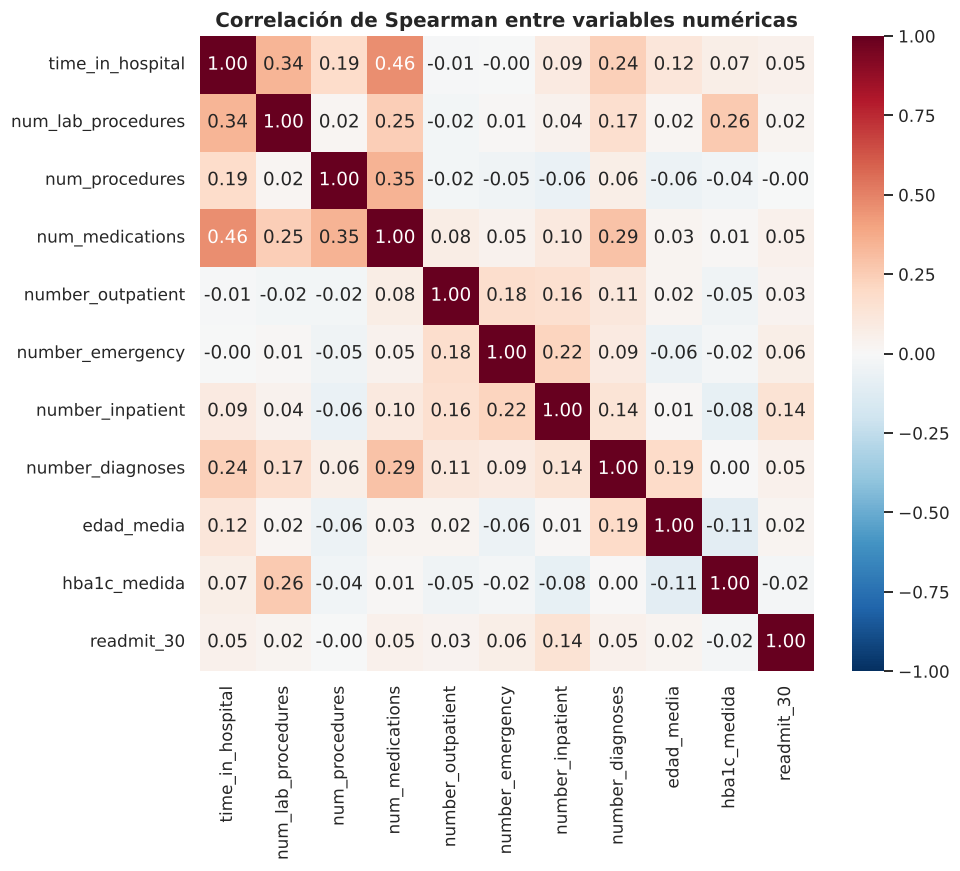

number_inpatient      0.141
number_emergency      0.064
time_in_hospital      0.053
number_diagnoses      0.052
num_medications       0.048
number_outpatient     0.035
edad_media            0.024
num_lab_procedures    0.024
num_procedures       -0.005
hba1c_medida         -0.021
Name: readmit_30, dtype: float64


In [14]:
corr = df[NUM + ["edad_media", "hba1c_medida", "readmit_30"]].corr(method="spearman")
plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman entre variables numéricas")
guardar("correlacion"); plt.show()
print(corr["readmit_30"].drop("readmit_30").sort_values(ascending=False).round(3))

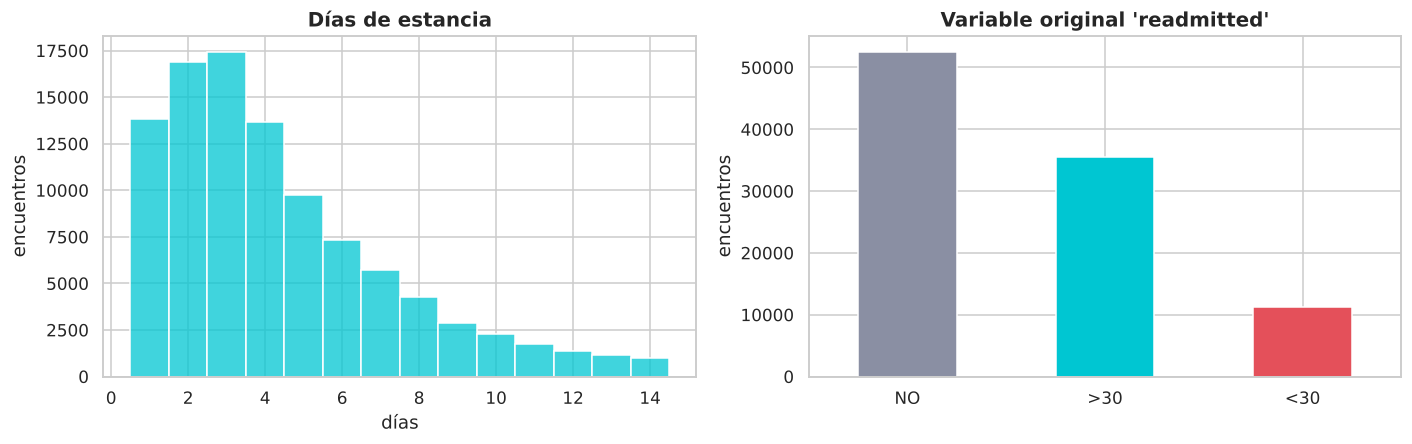

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(df.time_in_hospital, discrete=True, color=CYAN, ax=ax[0])
ax[0].set(title="Días de estancia", xlabel="días", ylabel="encuentros")
df.readmitted.value_counts().reindex(["NO", ">30", "<30"]).plot.bar(color=[GRAY, CYAN, RED], ax=ax[1], rot=0)
ax[1].set(title="Variable original 'readmitted'", ylabel="encuentros", xlabel="")
plt.tight_layout(); guardar("distribuciones"); plt.show()

### P1. Hospitalizaciones previas y readmisión temprana

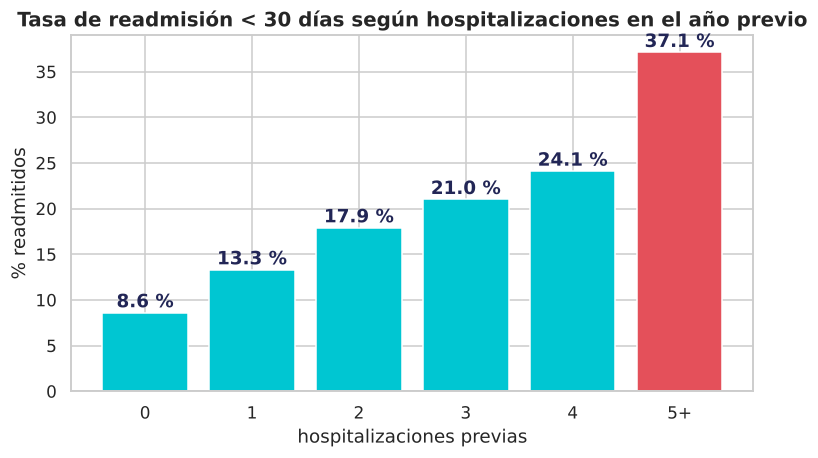

Spearman (todos los encuentros): rho = 0.141, p = < 1e-300 (por debajo de la precisión numérica)
Spearman (solo primer encuentro por paciente): rho = 0.085, p = 3.1e-111
Riesgo relativo 5+ vs 0 hospitalizaciones: 4.3 veces


In [16]:
t1 = p1.toPandas()
plt.figure(figsize=(8, 4.2))
plt.bar(t1.hosp_previas, t1.tasa_readmision_pct, color=[CYAN]*5 + [RED])
for x, y in zip(t1.hosp_previas, t1.tasa_readmision_pct):
    plt.text(x, y + 0.6, f"{y:.1f} %", ha="center", fontweight="bold", color=NAVY)
plt.title("Tasa de readmisión < 30 días según hospitalizaciones en el año previo")
plt.xlabel("hospitalizaciones previas"); plt.ylabel("% readmitidos")
guardar("p1_hospitalizaciones"); plt.show()

rho, p = stats.spearmanr(df.number_inpatient, df.readmit_30)
pe = df[df.primer_encuentro == 1]
rho1, p_1 = stats.spearmanr(pe.number_inpatient, pe.readmit_30)
print(f"Spearman (todos los encuentros): rho = {rho:.3f}, p = {fmt_p(p)}")
print(f"Spearman (solo primer encuentro por paciente): rho = {rho1:.3f}, p = {fmt_p(p_1)}")
r0, r5 = t1.set_index("hosp_previas").loc[["0", "5+"], "tasa_readmision_pct"]
print(f"Riesgo relativo 5+ vs 0 hospitalizaciones: {r5/r0:.1f} veces")

### P2. Medición de HbA1c y readmisión temprana

Con HbA1c medida: 9.94 %  |  sin medir: 11.69 %  |  medida en 16.9 % de los encuentros
Chi-cuadrado = 42.1, p = 8.6e-11
Solo primer encuentro: con HbA1c 8.40 % | sin 9.11 % | p = 1.1e-02


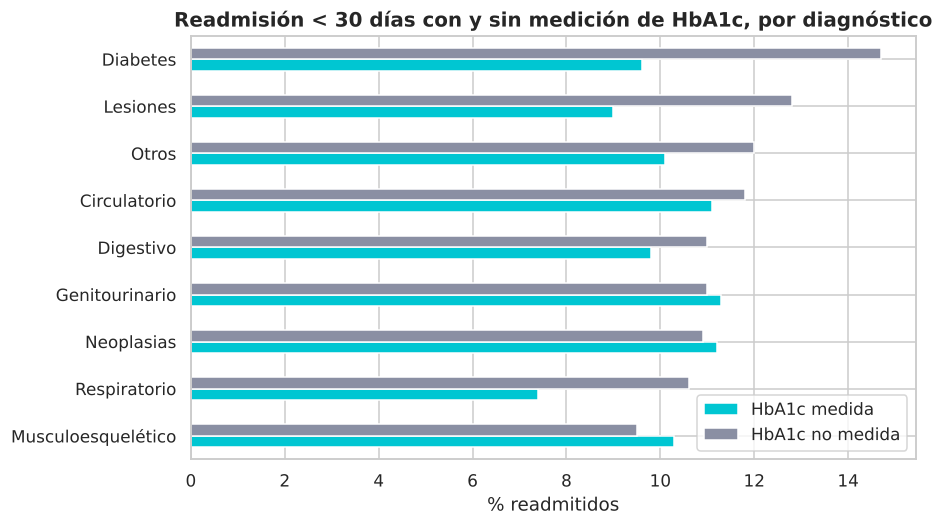

In [17]:
tab = pd.crosstab(df.hba1c_medida, df.readmit_30)
chi2, p, _, _ = stats.chi2_contingency(tab)
tasas = df.groupby("hba1c_medida").readmit_30.mean() * 100
print(f"Con HbA1c medida: {tasas[1]:.2f} %  |  sin medir: {tasas[0]:.2f} %  |  medida en {df.hba1c_medida.mean()*100:.1f} % de los encuentros")
print(f"Chi-cuadrado = {chi2:.1f}, p = {p:.1e}")
tab1 = pd.crosstab(pe.hba1c_medida, pe.readmit_30); chi2b, pb, _, _ = stats.chi2_contingency(tab1)
print(f"Solo primer encuentro: con HbA1c {pe[pe.hba1c_medida==1].readmit_30.mean()*100:.2f} % | sin {pe[pe.hba1c_medida==0].readmit_30.mean()*100:.2f} % | p = {pb:.1e}")

t2 = p2_diag.toPandas().set_index("diag_principal_grupo")[["tasa_con_hba1c", "tasa_sin_hba1c"]].sort_values("tasa_sin_hba1c")
t2.plot.barh(color=[CYAN, GRAY], figsize=(8.5, 5))
plt.title("Readmisión < 30 días con y sin medición de HbA1c, por diagnóstico")
plt.xlabel("% readmitidos"); plt.ylabel(""); plt.legend(["HbA1c medida", "HbA1c no medida"])
guardar("p2_hba1c"); plt.show()

### P3. Edad, estancia, medicamentos y readmisión

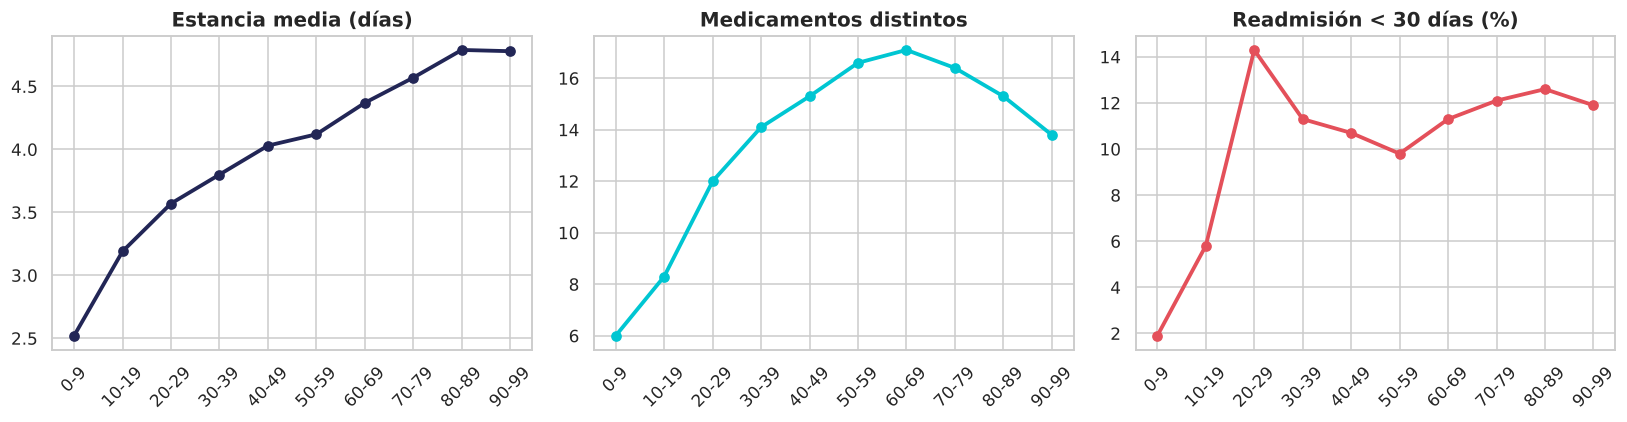

Kruskal-Wallis, estancia entre grupos de edad: H = 1556, p = < 1e-300 (por debajo de la precisión numérica)
Readmisión 60+: 11.93 % | menores de 60: 10.31 %
Estancia 60+: 4.57 días | menores de 60: 4.00 días


In [18]:
t3 = p3.toPandas()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, titulo, color in zip(ax, ["estancia_media_dias", "medicamentos_medios", "tasa_readmision_pct"],
                                 ["Estancia media (días)", "Medicamentos distintos", "Readmisión < 30 días (%)"],
                                 [NAVY, CYAN, RED]):
    a.plot(t3.grupo_edad, t3[col], marker="o", color=color, lw=2.5)
    a.set_title(titulo); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); guardar("p3_edad"); plt.show()

kw = stats.kruskal(*[g.time_in_hospital for _, g in df.groupby("grupo_edad")])
print(f"Kruskal-Wallis, estancia entre grupos de edad: H = {kw.statistic:.0f}, p = {fmt_p(kw.pvalue)}")
mayores = df.edad_media >= 60
print(f"Readmisión 60+: {df[mayores].readmit_30.mean()*100:.2f} % | menores de 60: {df[~mayores].readmit_30.mean()*100:.2f} %")
print(f"Estancia 60+: {df[mayores].time_in_hospital.mean():.2f} días | menores de 60: {df[~mayores].time_in_hospital.mean():.2f} días")

### P4. Diagnóstico principal y destino de egreso

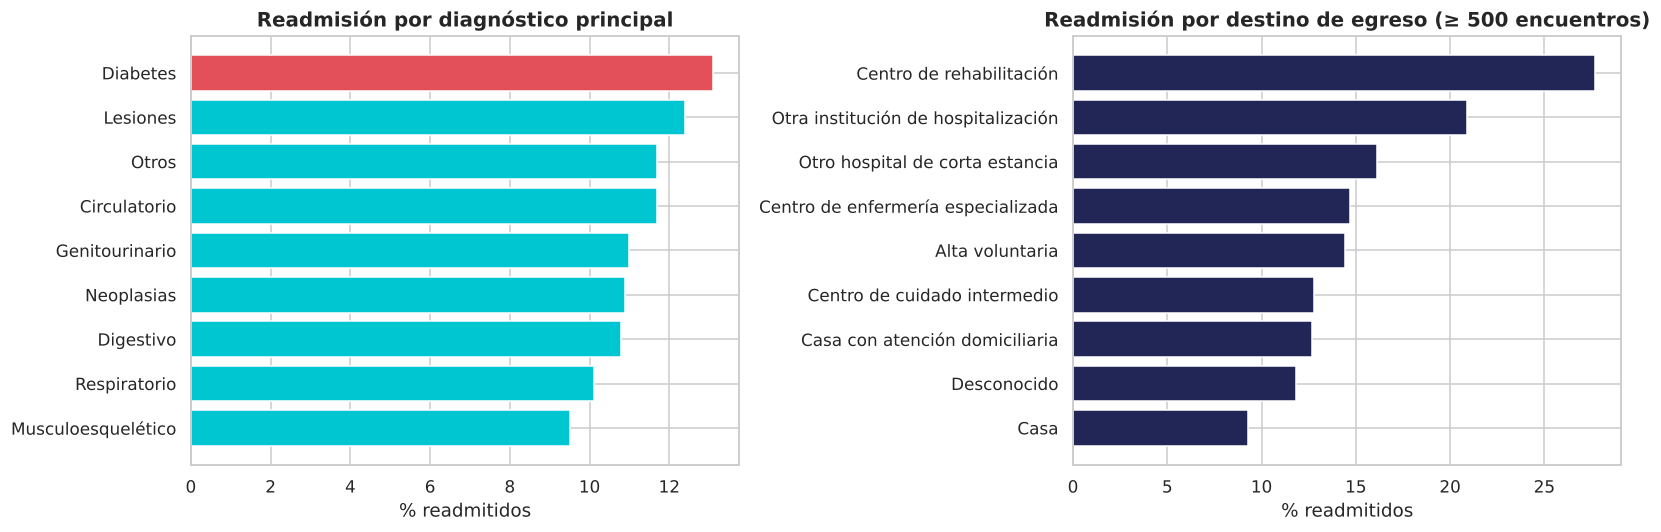

Chi-cuadrado diagnóstico vs readmisión: 82.0, p = 2.0e-14
Egreso a casa: 9.30 % | otros destinos: 14.61 %


In [19]:
t4d = p4_diag.toPandas().sort_values("tasa_readmision_pct")
t4e = p4_egreso.toPandas().sort_values("tasa_readmision_pct")
t4e["egreso"] = t4e.discharge_disposition
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(t4d.diag_principal_grupo, t4d.tasa_readmision_pct, color=[RED if g == "Diabetes" else CYAN for g in t4d.diag_principal_grupo])
ax[0].set(title="Readmisión por diagnóstico principal", xlabel="% readmitidos")
ax[1].barh(t4e.egreso, t4e.tasa_readmision_pct, color=NAVY)
ax[1].set(title="Readmisión por destino de egreso (≥ 500 encuentros)", xlabel="% readmitidos")
plt.tight_layout(); guardar("p4_diagnostico_egreso"); plt.show()

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df.diag_principal_grupo, df.readmit_30))
print(f"Chi-cuadrado diagnóstico vs readmisión: {chi2:.1f}, p = {p:.1e}")
casa = df.discharge_disposition == "Casa"
print(f"Egreso a casa: {df[casa].readmit_30.mean()*100:.2f} % | otros destinos: {df[~casa].readmit_30.mean()*100:.2f} %")

## Electiva E. Estimación sencilla de valor

In [20]:
# Supuestos explícitos (no salen del dataset):
COSTO_READMISION_USD = 15_200   # costo promedio de una readmisión a 30 días en adultos, EE. UU. 2018 (Weiss y Jiang, 2021)
REDUCCION = 0.10                # un programa de seguimiento evita el 10 % de las readmisiones del grupo intervenido

grupo = df[df.number_inpatient >= 2]
readm = grupo.readmit_30.sum()
evitadas = readm * REDUCCION
print(f"Grupo objetivo (2+ hospitalizaciones previas): {len(grupo):,} encuentros ({len(grupo)/len(df)*100:.1f} %) "
      f"que concentran {readm:,} readmisiones ({readm/df.readmit_30.sum()*100:.1f} % del total)")
print(f"Readmisiones evitadas con una reducción del 10 %: {evitadas:,.0f}")
print(f"Costo evitado estimado: USD {evitadas*COSTO_READMISION_USD:,.0f} en los 10 años del dataset "
      f"(≈ USD {evitadas*COSTO_READMISION_USD/10:,.0f} por año)")

Grupo objetivo (2+ hospitalizaciones previas): 14,114 encuentros (14.2 %) que concentran 3,108 readmisiones (27.5 % del total)
Readmisiones evitadas con una reducción del 10 %: 311
Costo evitado estimado: USD 4,724,160 en los 10 años del dataset (≈ USD 472,416 por año)


## T9. Conclusiones, limitaciones y recomendaciones

*Cada cifra sale de las celdas anteriores.*

- **P1:** la readmisión temprana crece de forma sostenida con las hospitalizaciones previas: 8,6 % sin hospitalizaciones previas frente a 37,1 % con 5 o más (4,3 veces más). Es la variable con mayor correlación con la readmisión (ρ de Spearman = 0,14) y la relación se mantiene, más débil, al usar solo el primer encuentro de cada paciente (ρ = 0,09).
- **P2:** la HbA1c se midió solo en 16,9 % de los encuentros. Cuando se midió, la readmisión fue 9,9 % frente a 11,7 % cuando no se midió (χ², p ≈ 8,6 × 10⁻¹¹; con solo el primer encuentro, 8,4 % frente a 9,1 %, p = 0,01). La diferencia es pequeña y cambia según el diagnóstico: es mayor en pacientes hospitalizados por diabetes (9,6 % frente a 14,7 %), lo que coincide con Strack et al. (2014).
- **P3:** la estancia media aumenta con la edad (de 2,5 días en menores de 10 años a 4,8 días en 80–89), y la readmisión es mayor en pacientes de 60 años o más (11,9 %) que en los menores de 60 (10,3 %). Las diferencias de estancia entre grupos son significativas (Kruskal-Wallis).
- **P4:** los pacientes hospitalizados por diabetes como diagnóstico principal tienen la tasa más alta (13,1 %), y el destino de egreso pesa más que el diagnóstico: los remitidos a un centro de rehabilitación se readmiten 27,7 % frente a 9,3 % de quienes vuelven a casa.
- **Valor (Electiva E):** los pacientes con 2 o más hospitalizaciones previas son 14,2 % de los encuentros pero concentran 27,5 % de las readmisiones; reducir en 10 % sus readmisiones evitaría unas 311 readmisiones, del orden de USD 4,7 millones en los 10 años del dataset con el costo promedio de HCUP.

**Limitaciones:** datos de EE. UU. entre 1999 y 2008, sin variables clínicas de laboratorio completas; no se puede generalizar directamente a hospitales colombianos; las asociaciones no son causales; el atributo de readmisión solo captura readmisiones en los hospitales de la red.

**Recomendaciones:** priorizar el seguimiento post-egreso de pacientes con 2 o más hospitalizaciones en el último año; volver rutinaria la medición de HbA1c en pacientes diabéticos hospitalizados; reforzar la coordinación con instituciones de rehabilitación y cuidado especializado al momento del egreso.

In [21]:
spark.stop()